In [116]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import requests

In [117]:
folder = r"C:\Users\cs_fondation\Documents\DatathonBCGX"
file = "trafic_3_arcs_complet.csv"

In [118]:
data = pd.read_csv(f"{folder}/{file}")

C:\Users\cs_fondation\AppData\Local\Temp\ipykernel_6620\3501030540.py:1: DtypeWarning: Columns (9: etat_arc) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(f"{folder}/{file}")


In [119]:
columns_to_keep = ["axe", "arc_id", "datetime_utc", "debit", "occupation", "etat_trafic", "etat_arc_code", "ligne_absente", "source", "etat_arc"]

In [120]:
df = data[columns_to_keep].rename(columns={
    "datetime_utc": "datetime",
    "debit": "flow",
    "occupation": "occupancy",
    "etat_trafic": "traffic_state",
    "etat_arc": "arc_state"
})
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df["open_arc"] = df["arc_state"].eq("Ouvert")

In [121]:
df["traffic_state"] = df["traffic_state"].astype("category")

In [122]:
df = df.sort_values(["axe", "datetime"]).reset_index(drop=True)

In [123]:
df = df.drop(columns=["arc_state"])

In [124]:
df.reset_index(drop=True, inplace=True)

In [125]:
#Récuperer les données jours fériés

all_holidays = []

for year in range(2014, 2027):

    url = f"https://calendrier.api.gouv.fr/jours-feries/metropole/{year}.json"

    response = requests.get(url)

    holidays = response.json()

    for date, name in holidays.items():

        all_holidays.append({
            "date": pd.to_datetime(date),
            "holiday_name": name,
            "is_holiday": 1
        })

holidays_df = pd.DataFrame(all_holidays)

holidays_df.to_csv("french_holidays_2014_2026.csv", index=False)

In [126]:
#Récupérer les données de vacances scolaires

from vacances_scolaires_france import SchoolHolidayDates

d = SchoolHolidayDates()

dates = pd.date_range(
    start="2014-01-01",
    end="2026-11-01",
    freq="D"
)

vacances = []

for date in dates:

    vacances.append({
        "date": date.date(),
        "is_school_holiday":
            int(d.is_holiday_for_zone(
                date.date(),
                "C"
            ))
    })

vacances_df = pd.DataFrame(vacances)

vacances_df.to_csv(
    "vacances_zone_c_2014_2026.csv",
    index=False
)

In [127]:
#Recuperer les données meteo 

weather_all = []

for year in range(2014, 2027):

    start = f"{year}-01-01"

    if year == 2026:
        end = "2026-11-01"
    else:
        end = f"{year}-12-31"

    params = {
        "latitude":48.8566,
        "longitude":2.3522,
        "timezone":"Europe/Paris",
        "start_date":start,
        "end_date":end,
        "hourly":",".join([
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "rain",
            "snowfall",
            "cloud_cover",
            "wind_speed_10m"
        ])
    }

    url = "https://archive-api.open-meteo.com/v1/archive"

    data = requests.get(
        url,
        params=params
    ).json()

    yearly = pd.DataFrame(data["hourly"])

    weather_all.append(yearly)

weather = pd.concat(
    weather_all,
    ignore_index=True
)

weather["time"] = pd.to_datetime(
    weather["time"]
)

weather.to_csv(
    "weather_paris_2014_2026.csv",
    index=False
)

In [128]:
# Features temporelles calculees en heure locale de Paris.
traffic = df.copy()
traffic["datetime_local"] = traffic["datetime"].dt.tz_convert("Europe/Paris")
local_datetime = traffic["datetime_local"]

traffic["hour"] = local_datetime.dt.hour
traffic["weekday"] = local_datetime.dt.dayofweek
traffic["month"] = local_datetime.dt.month
traffic["year"] = local_datetime.dt.year
traffic["week"] = local_datetime.dt.isocalendar().week
traffic["is_weekend"] = (traffic["weekday"] >= 5).astype(int)

In [129]:
traffic["date"] = traffic["datetime_local"].dt.date

holidays = holidays_df[["date", "is_holiday"]].copy()
holidays["date"] = pd.to_datetime(holidays["date"], errors="raise").dt.date
school_holidays = vacances_df[["date", "is_school_holiday"]].copy()
school_holidays["date"] = pd.to_datetime(
    school_holidays["date"], errors="raise"
).dt.date

traffic = traffic.merge(
    holidays, on="date", how="left", validate="many_to_one"
)
traffic["is_holiday"] = traffic["is_holiday"].fillna(0).astype(int)

traffic = traffic.merge(
    school_holidays, on="date", how="left", validate="many_to_one"
)
traffic["is_school_holiday"] = (
    traffic["is_school_holiday"].fillna(0).astype(int)
)

weather_hourly = weather.rename(columns={"time": "_weather_time"}).copy()
weather_hourly["_weather_time"] = pd.to_datetime(
    weather_hourly["_weather_time"], errors="raise"
)
traffic["_weather_time"] = traffic["datetime_local"].dt.tz_localize(None)
traffic = traffic.merge(
    weather_hourly,
    on="_weather_time",
    how="left",
    validate="many_to_one"
).drop(columns="_weather_time")

traffic = traffic.sort_values(["axe", "datetime"]).reset_index(drop=True)
hourly_steps = traffic.groupby("axe", sort=False)["datetime"].diff().dropna()
traffic.to_csv(f"{folder}/traffic_data_with_features.csv", index=False)

corr = traffic.select_dtypes('number').corr()

print(corr["flow"].sort_values())
print(corr["occupancy"].sort_values())


relative_humidity_2m   -0.211966
year                   -0.194938
is_weekend             -0.088754
is_school_holiday      -0.082879
is_holiday             -0.056340
weekday                -0.051542
snowfall               -0.005615
week                    0.000901
month                   0.001024
precipitation           0.007940
rain                    0.008469
cloud_cover             0.050141
wind_speed_10m          0.087591
etat_arc_code           0.110505
temperature_2m          0.120155
arc_id                  0.179977
hour                    0.373406
occupancy               0.526952
flow                    1.000000
Name: flow, dtype: float64
relative_humidity_2m   -0.176427
is_weekend             -0.097315
is_school_holiday      -0.094692
weekday                -0.049023
is_holiday             -0.044283
snowfall               -0.000914
precipitation           0.025345
rain                    0.025559
year                    0.040798
arc_id                  0.045745
cloud_cover     

In [130]:
traffic["hour"] = traffic["datetime"].dt.hour
traffic["weekday"] = traffic["datetime"].dt.dayofweek
traffic["month"] = traffic["datetime"].dt.month

traffic["is_weekend"] = (traffic["weekday"] >= 5).astype(int)

traffic.groupby(traffic["rain"] > 0)["occupancy"].mean()

rain
False    8.272651
True     9.328317
Name: occupancy, dtype: float64

In [131]:
traffic.groupby("weekday")["flow"].mean()

weekday
0    639.121379
1    679.773268
2    694.460644
3    703.192353
4    713.697039
5    631.709096
6    534.752540
Name: flow, dtype: float64

In [132]:
traffic.groupby("hour")["flow"].mean()

hour
0     424.176311
1     324.630771
2     243.120020
3     189.278814
4     198.546770
5     300.040089
6     486.493866
7     678.652573
8     783.432282
9     803.945583
10    822.995326
11    859.428928
12    863.111314
13    863.959745
14    891.842314
15    908.935316
16    921.922995
17    943.801033
18    950.129736
19    872.397653
20    718.064641
21    612.032173
22    581.130517
23    527.441728
Name: flow, dtype: float64

<Axes: xlabel='hour'>

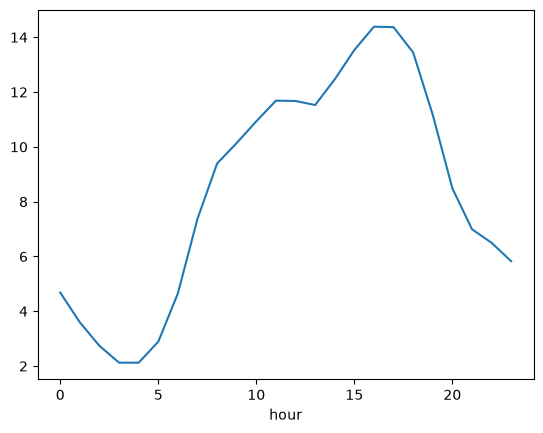

In [133]:
traffic.groupby("hour")["occupancy"].mean().plot()

<Axes: xlabel='weekday'>

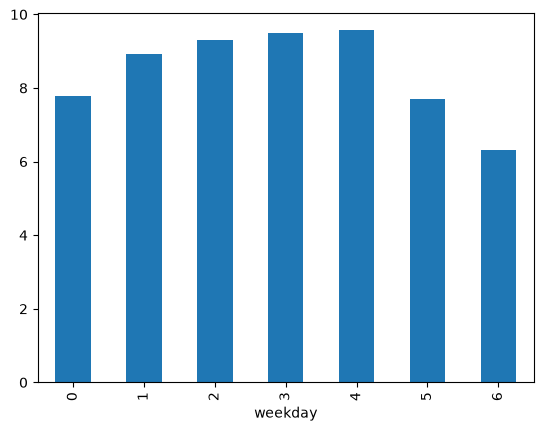

In [134]:
traffic.groupby("weekday")["occupancy"].mean().plot.bar()